# SAE "Analyse automatique de données" -- Notebook 3 : classification multiclasse

Dans ce notebook, vous devez :
1. Effectuer des expérimentations pour optimiser les paramètres du classifieur choisi (k plus proche voisin ou arbre de décision) pour effectuer une classification multiclasse des avis ;
2. [Bonus] Effectuer des expérimentations supplémentaires avec d'autres classifieurs (l'autre classifieur vu en cours ou d'autres classifieurs de `scikit-learn`) ;
3. Rédiger une synthèse pour justifier des pré-traitements effectués, du choix du regroupement des notes pour obtenir vos classes et des valeurs des paramètres obtenus pour vos classifieurs. Vous concluerez sur le meilleur choix des pré-traitements, des classes binaires et des paramètres de votre ou vos classifieurs.


Faites attention à la prise en compte du déséquilibre que vous pourriez avoir entre vos classes, en termes de nombre d'avis dans chacune des classes. 
Vous pouvez notamment utiliser le module python `imbalanced-learn` pour tester différentes manières de gérer les déséquilibres entre classes.
	
Vous pouvez également tout d'abord considérer un sous-ensemble de votre ensemble d'apprentissage, pour mettre au point chacune de vos expérimentations.
			


## Modules python utilisés

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler
from sklearn.model_selection import train_test_split
import spacy


## 1. Classification multiclasse avec le classifieur Arbre de décisions

In [5]:
# On refait toute la démarche afin de rééquilibrer parfaitement les données pour les 5 notes afin d'avoir un résultat le plus optimal possible
# Le fichier a été téléchargé sur https://huggingface.co/datasets/debojit01/fake-review-dataset/tree/main
fake_review_df = pd.read_csv("data/fake_reviews.csv")
# Affichage des headers
fake_review_df.columns.values.tolist()

['category', 'rating', 'label', 'text_']

In [6]:
# Valeurs nulles
fake_review_df.dropna()

# CG = 0 et OR = 1
fake_review_df.loc[fake_review_df["label"] ==  "CG", "label"] = 0
fake_review_df.loc[fake_review_df["label"] ==  "OR", "label"] = 1

# Assure que la colonne est de type int
fake_review_df['label'] = fake_review_df['label'].astype(int)

print(f"Avant équilibrage: {fake_review_df['rating'].value_counts()}")

# On supprime des données pour 1,3,4 et 5 afin d'en avoir autant que le minumun (2). Le but est que chaque colonne a ensuite 1967 données
fake_review_df.drop(fake_review_df[fake_review_df['rating'] == 5.0].sample(n=22592).index,inplace=True)
fake_review_df.drop(fake_review_df[fake_review_df['rating'] == 4.0].sample(n=5998).index,inplace=True)
fake_review_df.drop(fake_review_df[fake_review_df['rating'] == 3.0].sample(n=1819).index,inplace=True)
fake_review_df.drop(fake_review_df[fake_review_df['rating'] == 1.0].sample(n=188).index,inplace=True)

print(f"Après équilibrage: {fake_review_df['rating'].value_counts()}")

Avant équilibrage: rating
5.0    24559
4.0     7965
3.0     3786
1.0     2155
2.0     1967
Name: count, dtype: int64
Après équilibrage: rating
3.0    1967
5.0    1967
2.0    1967
1.0    1967
4.0    1967
Name: count, dtype: int64


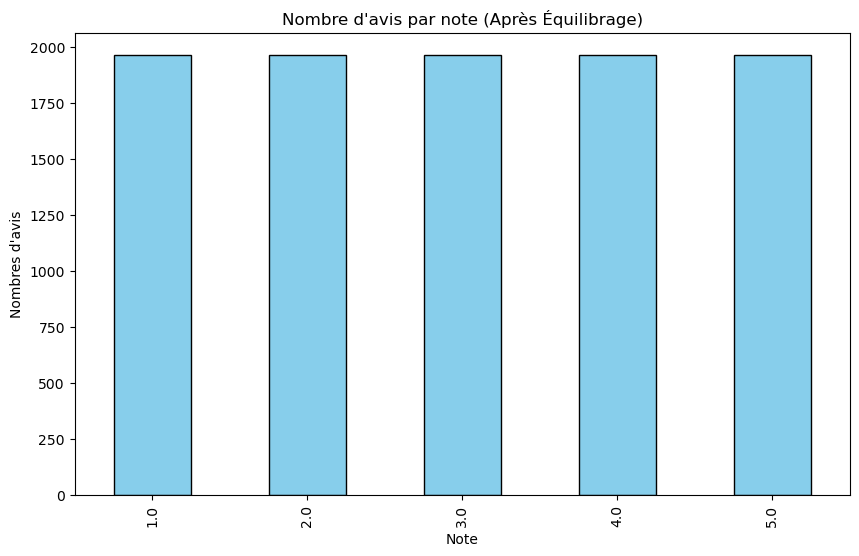

In [7]:
# Visualisation des données après répartition
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(10, 6))

# Nombre d'avis
fake_review_df['rating'].value_counts().sort_index().plot(
    kind='bar',
    ax=ax, # Utilisation de l'axe unique 'ax'
    color='skyblue',
    edgecolor='black',
    title="Nombre d'avis par note (Après Équilibrage)",
    xlabel='Note',
    ylabel="Nombres d'avis"
)

plt.show()

In [17]:
X = fake_review_df[['category', 'text_','label']]
y = fake_review_df['rating']

# On isole l'ensemble de train et de validation de l'ensemble de test
X_train_validation, X_test, y_train_validation, y_test = train_test_split(X, y,
                                                    stratify=y,
                                                    # Distribue les données de manière stratifiée = garantit que chaque sous ensemble à la même proportion de rating
                                                    test_size=0.1,
                                                    random_state=42)

# Séparation de l'ensemble de validation
# On prend 1/9 ème des 90% 
X_train, X_val, y_train, y_val = train_test_split(
    X_train_validation, y_train_validation,
    stratify=y_train_validation, 
    test_size=0.111, 
    random_state=42
)


nlp = spacy.load("en_core_web_sm") # Charger le package en_core_web_sm

def cleanData(texts):
    processed_texts = []
    for doc in nlp.pipe(texts):
        try:
            # On extrait la version lemmatisé
            tokens = [
                token.lemma_.lower() for token in doc
                if not token.is_stop and not token.is_punct  # Enlever les mots vides (that, is, the...) et les signes de ponctuations
                and token.pos_ in ["ADJ","ADV","VERB","NOUN"] # Garder les mots identifés comme Adverbes, adverbes, verbe, nom
            ]
            processed_texts.append(" ".join(tokens))
        except Exception as e :
            print(f"Erreur sur la phrase : {e}")
    return processed_texts

X_train['text_'] = cleanData(X_train['text_'])
X_test['text_'] = cleanData(X_test['text_'])

# Supprimer les lignes vides
X_train['text_'] = X_train['text_'].replace("", np.nan) 
X_test['text_'] = X_test['text_'].replace("", np.nan)

X_train = X_train.dropna(subset=['text_']).copy()
X_test = X_test.dropna(subset=['text_']).copy()

# Mettre à jour les df de résultats
y_train = y_train.loc[X_train.index]
y_test = y_test.loc[X_test.index]

/var/home/E232151N/.local/lib/python3.13/site-packages/spacy/util.py:969: UserWarning: [W095] Model 'en_core_web_sm' (3.7.1) was trained with spaCy v3.7.2 and may not be 100% compatible with the current version (3.8.11). If you see errors or degraded performance, download a newer compatible model or retrain your custom model with the current spaCy version. For more details and available updates, run: python -m spacy validate
  warnings.warn(warn_msg)


Démarrage de l'optimisation

Meilleurs paramètres trouvés : {'classifier__class_weight': None, 'classifier__criterion': 'entropy', 'classifier__max_depth': 15, 'classifier__min_samples_split': 5}
Meilleur score de validation (accuracy) : 0.266

Rapport de classification
              precision    recall  f1-score   support

Très Négatif       0.35      0.22      0.27       197
     Négatif       0.22      0.45      0.30       196
      Neutre       0.25      0.20      0.22       197
     Positif       0.23      0.15      0.18       197
Très Positif       0.35      0.31      0.33       197

    accuracy                           0.27       984
   macro avg       0.28      0.27      0.26       984
weighted avg       0.28      0.27      0.26       984



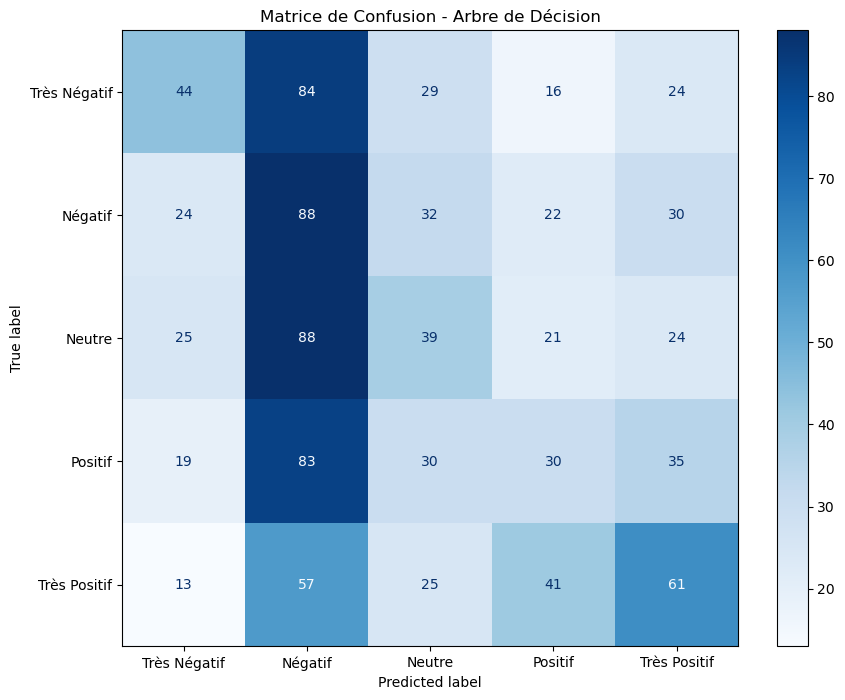

In [28]:
classes_noms = ['Très Négatif', 'Négatif', 'Neutre', 'Positif', 'Très Positif']

# ------------------------------------ Classifieur Arbre de décisions -----------------------------------

# Transformateurs pour les colonnes
preprocessor = ColumnTransformer(
    transformers=[
        ('text', TfidfVectorizer(max_features=2000, stop_words='english', min_df=100, # Ignorer les mots avec une rareté inférieur à 20
            ngram_range=(1,2), # Capte les expressions de 2 mots monogramme et bigramme
            use_idf=True), 'text_'),
        ('cat', OneHotEncoder(handle_unknown='ignore'), ['category'])
    ],
    remainder='drop'
)

# Gestion du déséquilibre

pipeline_dt = ImbPipeline([
    ('preprocessor', preprocessor),
    ('sampler', RandomOverSampler(random_state=42)),
    ('classifier', DecisionTreeClassifier(random_state=42))
])


# Grille de paramètres à tester
param_grid_dt = {
    'classifier__criterion': ['gini', 'entropy'],
    'classifier__max_depth': [5, 10, 15,30, 50 , 100, None],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__class_weight': [None, 'balanced'] # Aide l'arbre à pondérer les classes
}

# Recherche des meilleurs hyperparamètres
print("Démarrage de l'optimisation")
grid_dt = GridSearchCV(pipeline_dt, param_grid_dt, cv=3, scoring='accuracy', n_jobs=-1)
grid_dt.fit(X_train, y_train)

print(f"\nMeilleurs paramètres trouvés : {grid_dt.best_params_}")
print(f"Meilleur score de validation (accuracy) : {grid_dt.best_score_:.3f}")

# Évaluation sur le jeu de test avec le meilleur modèle
best_dt_model = grid_dt.best_estimator_
predictions_dt = best_dt_model.predict(X_test)

print("\nRapport de classification")
print(classification_report(y_test, predictions_dt, target_names=classes_noms))

# Matrice de confusion
fig, ax = plt.subplots(figsize=(10, 8)) 
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    predictions_dt, 
    display_labels=classes_noms,
    cmap='Blues',
    ax=ax
)
plt.title("Matrice de Confusion - Arbre de Décision")
plt.show()

## [Bonus] 2. Utilisation d'autres classifieurs multiclasse
 

Démarrage de l'optimisation KNN (peut être long)...
Meilleurs paramètres KNN : {'classifier__metric': 'cosine', 'classifier__n_neighbors': 50, 'classifier__weights': 'distance'}
Meilleur score validation : 0.274

Rapport KNN
              precision    recall  f1-score   support

Très Négatif       0.27      0.34      0.30       197
     Négatif       0.21      0.18      0.19       196
      Neutre       0.24      0.23      0.23       197
     Positif       0.30      0.30      0.30       197
Très Positif       0.33      0.30      0.32       197

    accuracy                           0.27       984
   macro avg       0.27      0.27      0.27       984
weighted avg       0.27      0.27      0.27       984



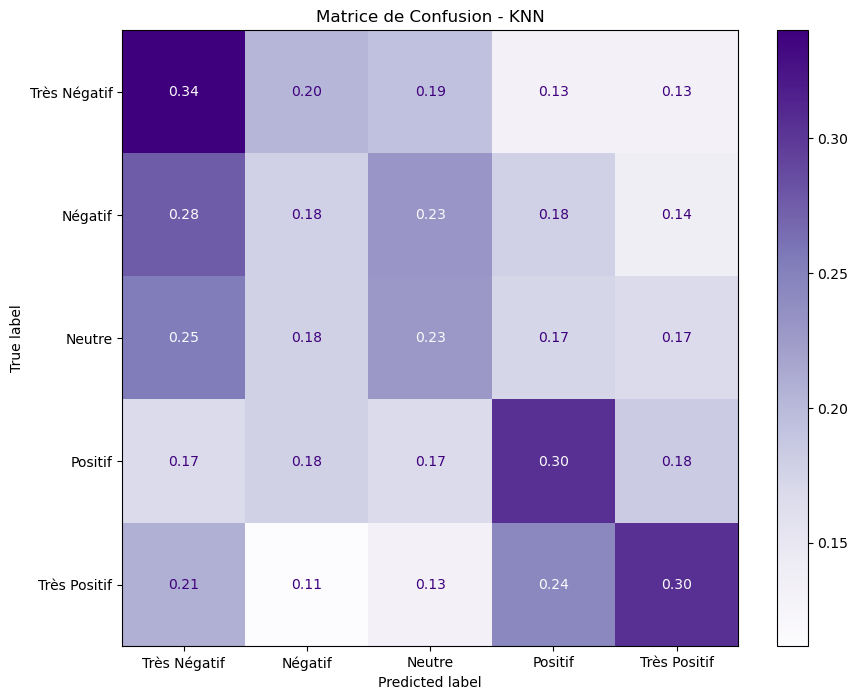

In [27]:
# ------------------------------------ Classifieur KNN -----------------------------------
preprocessor = ColumnTransformer(
    transformers=[
        ('text', TfidfVectorizer(max_features=5000, stop_words='english', ngram_range=(1, 2)), 'text_'),
        ('cat', OneHotEncoder(handle_unknown='ignore'), ['category'])
    ], remainder='drop'
)

# --- Pipeline KNN ---
pipeline_knn = ImbPipeline([
    ('preprocessor', preprocessor),
    ('sampler', RandomOverSampler(random_state=42)),
    ('classifier', KNeighborsClassifier()) # On configure les paramètres dans la grille
])

# --- Grille ---
param_grid_knn = {
    'classifier__n_neighbors': [5, 11, 20 , 50, 100],
    'classifier__weights': ['distance'],
    'classifier__metric': ['cosine']
}

print("Démarrage de l'optimisation KNN (peut être long)...")
grid_knn = GridSearchCV(pipeline_knn, param_grid_knn, cv=3, scoring='accuracy', n_jobs=-1)
grid_knn.fit(X_train, y_train)

print(f"Meilleurs paramètres KNN : {grid_knn.best_params_}")
print(f"Meilleur score validation : {grid_knn.best_score_:.3f}")

# --- Résultats ---
best_knn = grid_knn.best_estimator_
pred_knn = best_knn.predict(X_test)

print("\nRapport KNN")
print(classification_report(y_test, pred_knn, target_names=classes_noms))

fig, ax = plt.subplots(figsize=(10, 8)) 
ConfusionMatrixDisplay.from_predictions(y_test, pred_knn, display_labels=classes_noms, cmap='Purples', normalize='true', ax=ax, values_format='.2f')
plt.title("Matrice de Confusion - KNN")
plt.show()

Démarrage de l'optimisation Random Forest...
Meilleurs paramètres RF : {'classifier__max_depth': None, 'classifier__min_samples_leaf': 2, 'classifier__n_estimators': 100}
Meilleur score validation : 0.336

Rapport Random Forest
              precision    recall  f1-score   support

Très Négatif       0.38      0.45      0.41       197
     Négatif       0.30      0.23      0.26       196
      Neutre       0.27      0.23      0.25       197
     Positif       0.28      0.29      0.29       197
Très Positif       0.37      0.44      0.40       197

    accuracy                           0.33       984
   macro avg       0.32      0.33      0.32       984
weighted avg       0.32      0.33      0.32       984



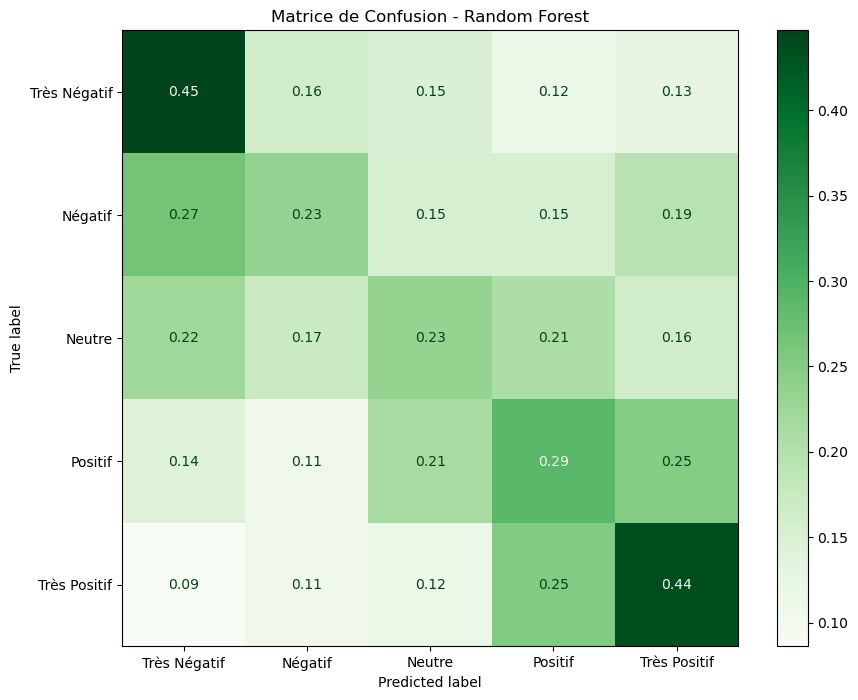

In [29]:
# ------------------------------------ Classifieur Random Forest -----------------------------------
preprocessor = ColumnTransformer(
    transformers=[
        ('text', TfidfVectorizer(max_features=5000, stop_words='english', ngram_range=(1, 2)), 'text_'),
        ('cat', OneHotEncoder(handle_unknown='ignore'), ['category'])
    ], remainder='drop'
)

# --- Pipeline Random Forest ---
pipeline_rf = ImbPipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42))
])

# --- Grille ---
param_grid_rf = {
    'classifier__n_estimators': [100],      # Nombre d'arbres
    'classifier__max_depth': [None, 10, 20,50],    # Profondeur max (None = apprend tout)
    'classifier__min_samples_leaf': [1, 2]  # Un peu de régularisation
}

print("Démarrage de l'optimisation Random Forest...")
grid_rf = GridSearchCV(pipeline_rf, param_grid_rf, cv=3, scoring='accuracy', n_jobs=-1)
grid_rf.fit(X_train, y_train)

print(f"Meilleurs paramètres RF : {grid_rf.best_params_}")
print(f"Meilleur score validation : {grid_rf.best_score_:.3f}")

# --- Résultats ---
best_rf = grid_rf.best_estimator_
pred_rf = best_rf.predict(X_test)

print("\nRapport Random Forest")
print(classification_report(y_test, pred_rf, target_names=classes_noms))

fig, ax = plt.subplots(figsize=(10, 8)) 
ConfusionMatrixDisplay.from_predictions(y_test, pred_rf, display_labels=classes_noms, cmap='Greens', normalize='true', ax=ax, values_format='.2f')
plt.title("Matrice de Confusion - Random Forest")
plt.show()

Démarrage de l'optimisation Régression Logistique...
Meilleurs paramètres LogReg : {'classifier__C': 1, 'classifier__solver': 'lbfgs'}
Meilleur score validation : 0.328

Rapport Régression Logistique
              precision    recall  f1-score   support

Très Négatif       0.38      0.43      0.40       197
     Négatif       0.32      0.30      0.31       196
      Neutre       0.28      0.23      0.25       197
     Positif       0.27      0.27      0.27       197
Très Positif       0.37      0.39      0.38       197

    accuracy                           0.33       984
   macro avg       0.32      0.33      0.32       984
weighted avg       0.32      0.33      0.32       984



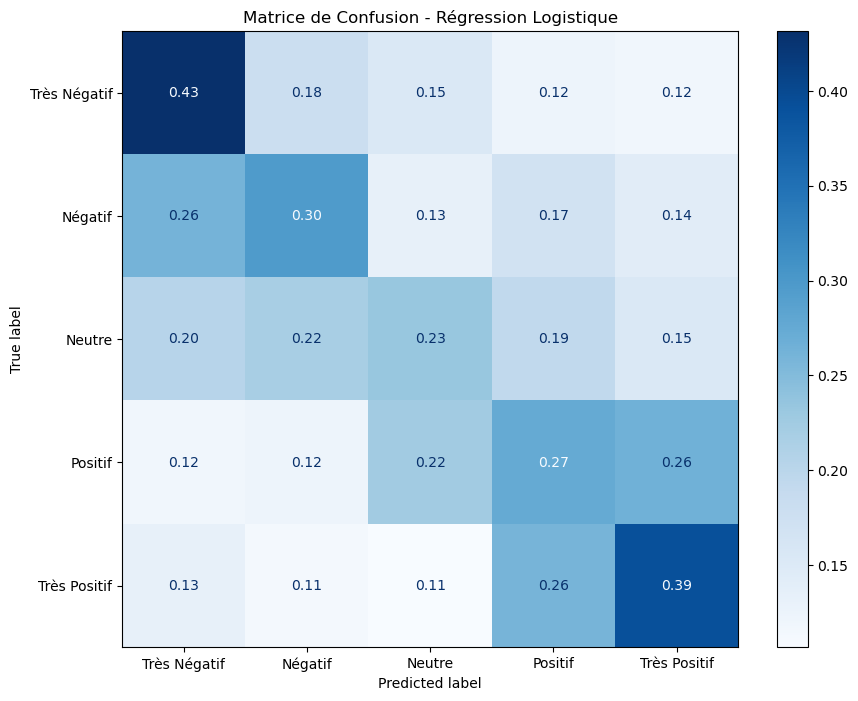

Exception ignored in: <function ResourceTracker.__del__ at 0x7f73fdfa8860>
Traceback (most recent call last):
  File "/usr/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/usr/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/usr/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x7fd40b8ac860>
Traceback (most recent call last):
  File "/usr/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/usr/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/usr/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x7f83804a4860>
Traceback (most recent call last):
  File "/usr/lib/python3.13/multiprocessing/reso

In [30]:
# ------------------------------------ Classifieur LogisticRegression -----------------------------------
preprocessor = ColumnTransformer(
    transformers=[
        ('text', TfidfVectorizer(max_features=5000, stop_words='english', ngram_range=(1, 2)), 'text_'),
        ('cat', OneHotEncoder(handle_unknown='ignore'), ['category'])
    ], remainder='drop'
)

# --- Pipeline LogReg ---
pipeline_lr = ImbPipeline([
    ('preprocessor', preprocessor),
    ('sampler', RandomOverSampler(random_state=42)),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

# --- Grille ---
param_grid_lr = {
    'classifier__C': [0.1, 1, 10],  # Paramètre clé : force de régularisation
    'classifier__solver': ['lbfgs']
}

print("Démarrage de l'optimisation Régression Logistique...")
grid_lr = GridSearchCV(pipeline_lr, param_grid_lr, cv=3, scoring='accuracy', n_jobs=-1)
grid_lr.fit(X_train, y_train)

print(f"Meilleurs paramètres LogReg : {grid_lr.best_params_}")
print(f"Meilleur score validation : {grid_lr.best_score_:.3f}")

# --- Résultats ---
best_lr = grid_lr.best_estimator_
pred_lr = best_lr.predict(X_test)

print("\nRapport Régression Logistique")
print(classification_report(y_test, pred_lr, target_names=classes_noms))

fig, ax = plt.subplots(figsize=(10, 8)) 
ConfusionMatrixDisplay.from_predictions(y_test, pred_lr, display_labels=classes_noms, cmap='Blues', normalize='true', ax=ax, values_format='.2f')
plt.title("Matrice de Confusion - Régression Logistique")
plt.show()

## 3. Synthèse des expérimentations et des résultats obtenus